In [13]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from shapely.geometry import Point

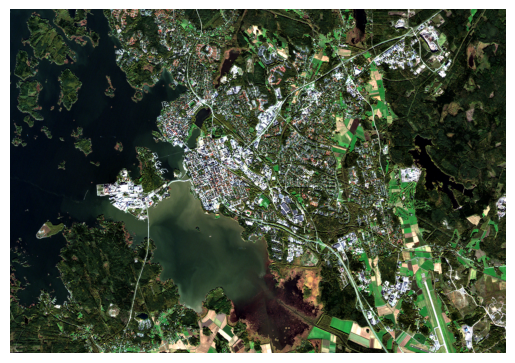

In [ ]:
#ZADANIE A)

path = "dane/Vaasa/"
with rasterio.open(path + "B04_red.tif") as src:
    red = src.read(1)
    transform = src.transform
    crs = src.crs
    meta = src.meta.copy()

with rasterio.open(path + "B03_green.tif") as src:
    green = src.read(1)

with rasterio.open(path + "B02_blue.tif") as src:
    blue = src.read(1)


rgb_stacked = np.stack([red, green, blue])
raster_rgb = np.moveaxis(rgb_stacked, 0, -1)
raster_rgb = raster_rgb / raster_rgb.max() * 255
raster_rgb2 = raster_rgb.astype(float).copy()
for i in range(3):
    low = np.percentile(raster_rgb2[:, :, i], 2)
    high = np.percentile(raster_rgb2[:, :, i], 98)

    raster_rgb2[:, :, i] = np.clip(
        (raster_rgb2[:, :, i] - low) / (high - low),
        0,
        1
    )
plt.imshow(raster_rgb2)
plt.axis("off")
plt.show()

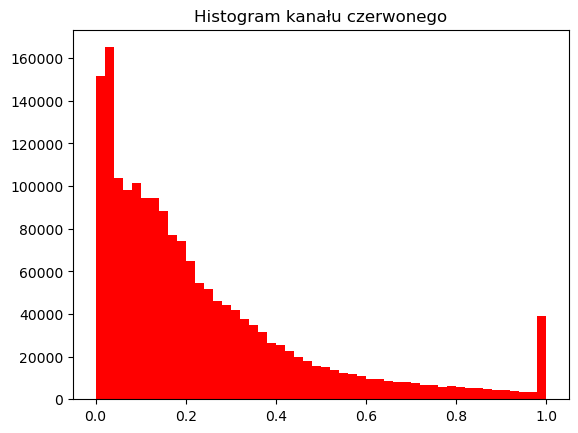

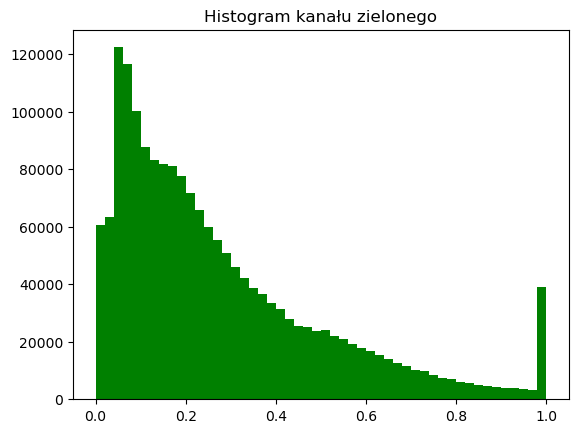

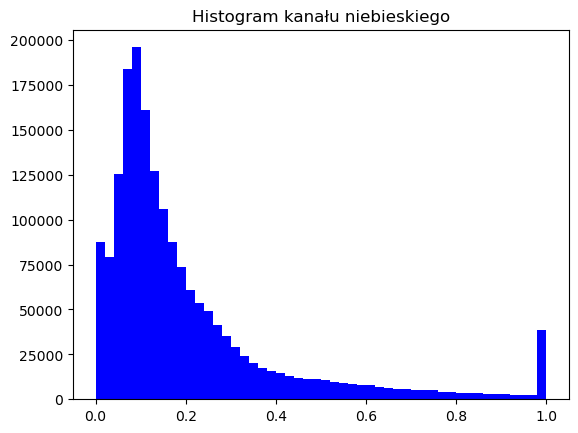

Histogramy dla wszystkich kanałów są wykresami asymetrycznymi, prawoskośnymi. Największe skupienia wartości pikseli występują dla wartości niskich, z gwałtownym skokiem dla wartości bliskich jeden. Najwięcej wystąpień mają wartości niebieskie, dla których, te bliskie 0,1, potrafią osiągać liczby rzędu prawie 200 tys. wystąpień


In [4]:
#ZADANIE B)

plt.hist(raster_rgb2[:, :, 0].flatten(), bins=50, color="red")
plt.title("Histogram kanału czerwonego")
plt.show()

plt.hist(raster_rgb2[:, :, 1].flatten(), bins=50, color="green")
plt.title("Histogram kanału zielonego")
plt.show()

plt.hist(raster_rgb2[:, :, 2].flatten(), bins=50, color="blue")
plt.title("Histogram kanału niebieskiego")
plt.show()

print("Histogramy dla wszystkich kanałów są wykresami asymetrycznymi, prawoskośnymi. Największe skupienia wartości pikseli występują dla wartości niskich, z gwałtownym skokiem dla wartości bliskich jeden. Najwięcej wystąpień mają wartości niebieskie, dla których, te bliskie 0,1, potrafią osiągać liczby rzędu prawie 200 tys. wystąpień")

In [ ]:
#ZADANIE C)

H, W = raster_rgb2.shape[:2]
row_edges = np.linspace(0, H, 4).round().astype(int)
col_edges = np.linspace(0, W, 4).round().astype(int)

parts = {}
records = []

for i in range(3):
    for j in range(3):
        r0, r1 = row_edges[i], row_edges[i + 1]
        c0, c1 = col_edges[j], col_edges[j + 1]

        parts[(i, j)] = raster_rgb2[r0:r1, c0:c1, :]

        row_c = (r0 + r1) / 2
        col_c = (c0 + c1) / 2

        x, y = transform * (col_c, row_c)

        records.append({
            "blok": f"{i},{j}",
            "x": x,
            "y": y
        })

for rec in records:
    print(f"Blok {rec['blok']}: x = {rec['x']:.2f}, y = {rec['y']:.2f}")

Blok 0,0: x = 527310.00, y = 6999735.00
Blok 0,1: x = 532690.00, y = 6999735.00
Blok 0,2: x = 538070.00, y = 6999735.00
Blok 1,0: x = 527310.00, y = 6996010.00
Blok 1,1: x = 532690.00, y = 6996010.00
Blok 1,2: x = 538070.00, y = 6996010.00
Blok 2,0: x = 527310.00, y = 6992285.00
Blok 2,1: x = 532690.00, y = 6992285.00
Blok 2,2: x = 538070.00, y = 6992285.00


In [ ]:
#ZADANIE D)

meta.update({
    "count": 3})

with rasterio.open("output/Vaasa.tif", 'w', **meta) as out:
    out.write(rgb_stacked)